**Fear Greed Text**

In [ ]:
from google.colab import files
files.upload()

Saving fear_greed_index.csv to fear_greed_index.csv


{'fear_greed_index.csv': b'timestamp,value,classification,date\r\n1517463000,30,Fear,2018-02-01\r\n1517549400,15,Extreme Fear,2018-02-02\r\n1517635800,40,Fear,2018-02-03\r\n1517722200,24,Extreme Fear,2018-02-04\r\n1517808600,11,Extreme Fear,2018-02-05\r\n1517895000,8,Extreme Fear,2018-02-06\r\n1517981400,36,Fear,2018-02-07\r\n1518067800,30,Fear,2018-02-08\r\n1518154200,44,Fear,2018-02-09\r\n1518240600,54,Neutral,2018-02-10\r\n1518327000,31,Fear,2018-02-11\r\n1518413400,42,Fear,2018-02-12\r\n1518499800,35,Fear,2018-02-13\r\n1518586200,55,Greed,2018-02-14\r\n1518672600,71,Greed,2018-02-15\r\n1518759000,67,Greed,2018-02-16\r\n1518845400,74,Greed,2018-02-17\r\n1518931800,63,Greed,2018-02-18\r\n1519018200,67,Greed,2018-02-19\r\n1519104600,74,Greed,2018-02-20\r\n1519191000,54,Neutral,2018-02-21\r\n1519277400,44,Fear,2018-02-22\r\n1519363800,39,Fear,2018-02-23\r\n1519450200,31,Fear,2018-02-24\r\n1519536600,33,Fear,2018-02-25\r\n1519623000,37,Fear,2018-02-26\r\n1519709400,44,Fear,2018-02-27\r\

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
data = pd.read_csv('fear_greed_index.csv')

In [ ]:
data.sample(2)

,timestamp,value,classification,date
1022,1606023000,94,Extreme Greed,2020-11-22
2444,1728883800,48,Neutral,2024-10-14


Random Forest Model - Accuracy: 0.78

Random Forest Model - Classification Report:
                precision    recall  f1-score   support

 Extreme Fear       0.81      0.86      0.84       111
Extreme Greed       0.81      0.90      0.85        67
         Fear       0.79      0.74      0.77       144
        Greed       0.79      0.73      0.76       131
      Neutral       0.64      0.67      0.65        76

     accuracy                           0.78       529
    macro avg       0.77      0.78      0.77       529
 weighted avg       0.78      0.78      0.77       529



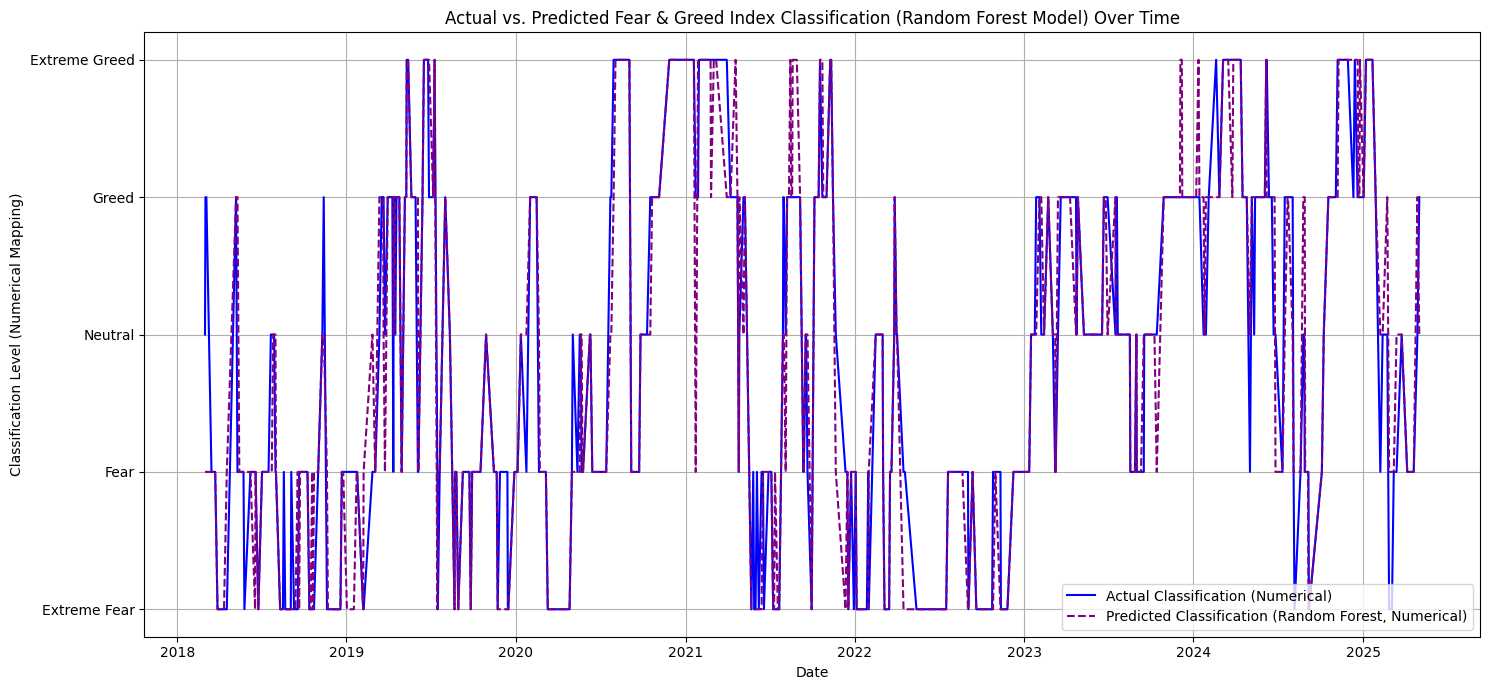

Random Forest model applied, evaluated, and predictions visualized successfully.


In [ ]:
 # Added LabelEncoder

# Load the data if not already loaded (assuming 'fear_greed_index.csv' is available)
# This section is added to ensure X_train, y_train, etc., are defined.
# If data is already loaded and processed in previous cells, this might be redundant but ensures code execution.
# It's better to ensure dependencies are met.
if 'data' not in locals():
    data = pd.read_csv('fear_greed_index.csv')

# 1. Convert the 'date' column to datetime objects
data['date'] = pd.to_datetime(data['date'])

# 2. Create a new numerical feature representing the time elapsed since the first date
data['time_elapsed_days'] = (data['date'] - data['date'].min()).dt.days

# 3. Define the features (X) and target (y)
X = data[['time_elapsed_days']]
y = data['classification'] # Changed target to 'classification'

# Encode the target variable for classification
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42) # Use y_encoded

# Initialize the Random Forest Classifier model
rf_model = RandomForestClassifier(random_state=42) # Changed to Classifier

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model using classification metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Model - Accuracy: {accuracy_rf:.2f}")
print("\nRandom Forest Model - Classification Report:\n", classification_report(y_test, y_pred_rf, target_names=le.classes_))

# Define a consistent numerical mapping for classification labels for plotting
classification_plot_mapping = {
    'Extreme Fear': 1,
    'Fear': 2,
    'Neutral': 3,
    'Greed': 4,
    'Extreme Greed': 5
}

# Convert encoded actual and predicted labels back to original string labels, then to numerical for plotting
y_test_original_labels = le.inverse_transform(y_test)
y_pred_rf_original_labels = le.inverse_transform(y_pred_rf)

y_test_plot_values = [classification_plot_mapping[label] for label in y_test_original_labels]
y_pred_rf_plot_values = [classification_plot_mapping[label] for label in y_pred_rf_original_labels]

# Create a DataFrame for plotting, combining the original 'date' column with the actual test values (y_test) and the predicted values (y_pred_rf)
plot_data_rf = pd.DataFrame({
    'date': data.loc[X_test.index, 'date'], # Use X_test index for dates
    'actual_value': y_test_plot_values,
    'predicted_value': y_pred_rf_plot_values
})

# Sort the DataFrame by date for correct time series plotting
plot_data_rf = plot_data_rf.sort_values(by='date')

# Plotting the actual vs. predicted values for the Random Forest model
plt.figure(figsize=(15, 7))
plt.plot(plot_data_rf['date'], plot_data_rf['actual_value'], label='Actual Classification (Numerical)', color='blue')
plt.plot(plot_data_rf['date'], plot_data_rf['predicted_value'], label='Predicted Classification (Random Forest, Numerical)', color='purple', linestyle='--')

plt.xlabel('Date')
plt.ylabel('Classification Level (Numerical Mapping)')
plt.title('Actual vs. Predicted Fear & Greed Index Classification (Random Forest Model) Over Time')
plt.yticks(list(classification_plot_mapping.values()), list(classification_plot_mapping.keys())) # Set y-ticks to show actual labels
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Random Forest model applied, evaluated, and predictions visualized successfully.")

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.

Logistic Regression Model - Accuracy: 0.32

Logistic Regression Model - Classification Report:
                precision    recall  f1-score   support

 Extreme Fear       0.00      0.00      0.00       111
Extreme Greed       0.00      0.00      0.00        67
         Fear       0.30      0.69      0.42       144
        Greed       0.34      0.52      0.41       131
      Neutral       0.00      0.00      0.00        76

     accuracy                           0.32       529
    macro avg       0.13      0.24      0.17       529
 weighted avg       0.17      0.32      0.22       529



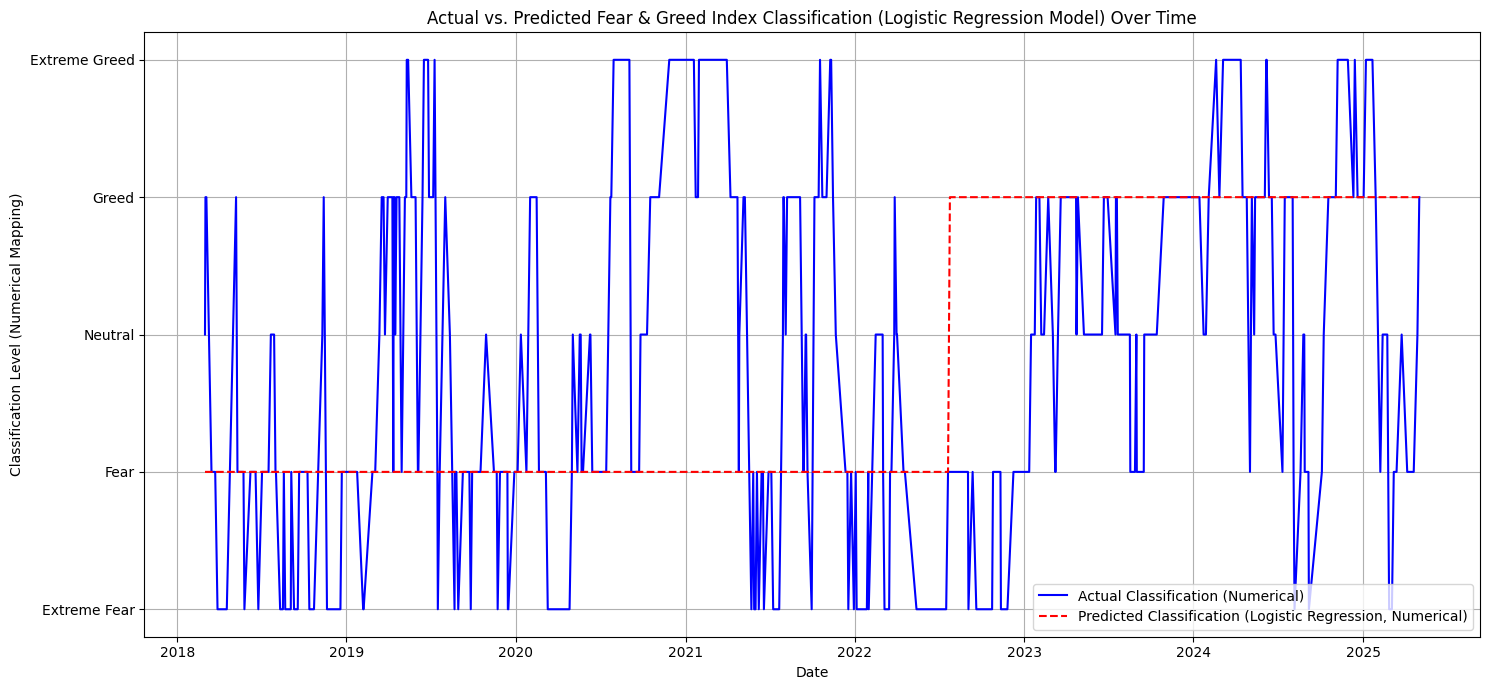

Logistic Regression model applied, evaluated, and predictions visualized successfully.


In [ ]:


# Initialize the Logistic Regression model
log_reg_model = LogisticRegression(random_state=42, solver='liblinear', multi_class='ovr') # 'liblinear' for small datasets, 'ovr' for multi-class

# Train the model
log_reg_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_log_reg = log_reg_model.predict(X_test)

# Evaluate the model using classification metrics
accuracy_log_reg = accuracy_score(y_test, y_pred_log_reg)
print(f"Logistic Regression Model - Accuracy: {accuracy_log_reg:.2f}")
print("\nLogistic Regression Model - Classification Report:\n", classification_report(y_test, y_pred_log_reg, target_names=le.classes_))

# Define a consistent numerical mapping for classification labels for plotting
classification_plot_mapping = {
    'Extreme Fear': 1,
    'Fear': 2,
    'Neutral': 3,
    'Greed': 4,
    'Extreme Greed': 5
}

# Convert encoded actual and predicted labels back to original string labels, then to numerical for plotting
y_test_original_labels = le.inverse_transform(y_test)
y_pred_log_reg_original_labels = le.inverse_transform(y_pred_log_reg)

y_test_plot_values = [classification_plot_mapping[label] for label in y_test_original_labels]
y_pred_log_reg_plot_values = [classification_plot_mapping[label] for label in y_pred_log_reg_original_labels]

# Create a DataFrame for plotting
plot_data_log_reg = pd.DataFrame({
    'date': data.loc[X_test.index, 'date'],
    'actual_value': y_test_plot_values,
    'predicted_value': y_pred_log_reg_plot_values
})

# Sort the DataFrame by date for correct time series plotting
plot_data_log_reg = plot_data_log_reg.sort_values(by='date')

# Plotting the actual vs. predicted values for the Logistic Regression model
plt.figure(figsize=(15, 7))
plt.plot(plot_data_log_reg['date'], plot_data_log_reg['actual_value'], label='Actual Classification (Numerical)', color='blue')
plt.plot(plot_data_log_reg['date'], plot_data_log_reg['predicted_value'], label='Predicted Classification (Logistic Regression, Numerical)', color='red', linestyle='--')

plt.xlabel('Date')
plt.ylabel('Classification Level (Numerical Mapping)')
plt.title('Actual vs. Predicted Fear & Greed Index Classification (Logistic Regression Model) Over Time')
plt.yticks(list(classification_plot_mapping.values()), list(classification_plot_mapping.keys()))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Logistic Regression model applied, evaluated, and predictions visualized successfully.")

Performing Grid Search for KNN... This might take a while.
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Grid Search complete for KNN.
Best parameters found for KNN: {'n_neighbors': 5, 'weights': 'distance'}
Best cross-validation Accuracy (from KNN grid search): 0.76

Tuned KNN Model - Accuracy: 0.82

Tuned KNN Model - Classification Report:
                precision    recall  f1-score   support

 Extreme Fear       0.86      0.87      0.87       111
Extreme Greed       0.88      0.87      0.87        67
         Fear       0.81      0.79      0.80       144
        Greed       0.83      0.84      0.83       131
      Neutral       0.72      0.72      0.72        76

     accuracy                           0.82       529
    macro avg       0.82      0.82      0.82       529
 weighted avg       0.82      0.82      0.82       529



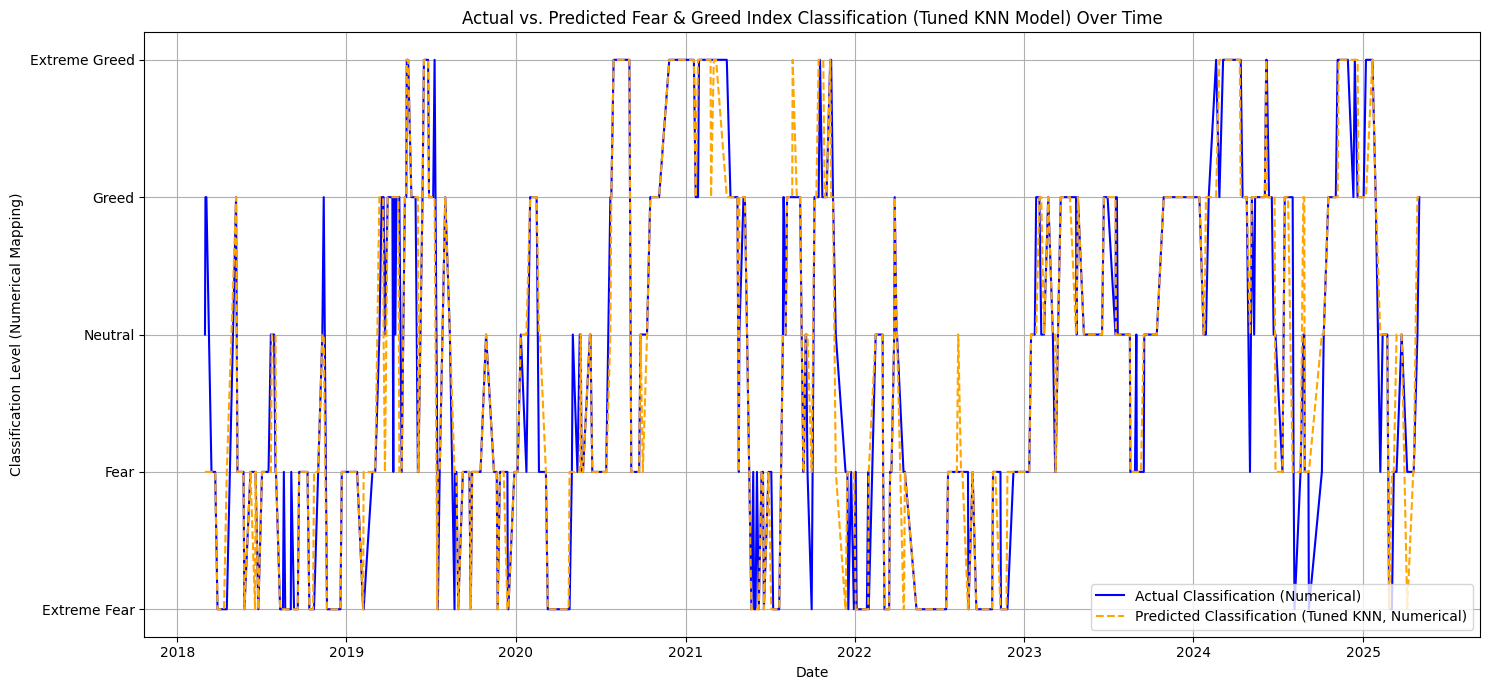

Tuned KNN model applied, evaluated, and predictions visualized successfully.


In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid to search for KNN
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 13],
    'weights': ['uniform', 'distance']
}

# Initialize the K-Nearest Neighbors Classifier
knn = KNeighborsClassifier()

# Initialize GridSearchCV
grid_search_knn = GridSearchCV(estimator=knn, param_grid=param_grid_knn, cv=3, n_jobs=-1, verbose=2, scoring='accuracy')

print("Performing Grid Search for KNN... This might take a while.")
grid_search_knn.fit(X_train, y_train)

print("Grid Search complete for KNN.")

# Get the best parameters and best score
best_params_knn = grid_search_knn.best_params_
best_accuracy_knn_cv = grid_search_knn.best_score_

print(f"Best parameters found for KNN: {best_params_knn}")
print(f"Best cross-validation Accuracy (from KNN grid search): {best_accuracy_knn_cv:.2f}")

# Train a new KNN model with the best parameters
knn_model_tuned = KNeighborsClassifier(**best_params_knn)
knn_model_tuned.fit(X_train, y_train)

# Make predictions on the test set using the tuned model
y_pred_knn_tuned = knn_model_tuned.predict(X_test)

# Evaluate the tuned model
accuracy_knn_tuned = accuracy_score(y_test, y_pred_knn_tuned)
print(f"\nTuned KNN Model - Accuracy: {accuracy_knn_tuned:.2f}")
print("\nTuned KNN Model - Classification Report:\n", classification_report(y_test, y_pred_knn_tuned, target_names=le.classes_))

# Define a consistent numerical mapping for classification labels for plotting
classification_plot_mapping = {
    'Extreme Fear': 1,
    'Fear': 2,
    'Neutral': 3,
    'Greed': 4,
    'Extreme Greed': 5
}

# Convert encoded actual and predicted labels back to original string labels, then to numerical for plotting
y_test_original_labels = le.inverse_transform(y_test)
y_pred_knn_tuned_original_labels = le.inverse_transform(y_pred_knn_tuned)

y_test_plot_values = [classification_plot_mapping[label] for label in y_test_original_labels]
y_pred_knn_tuned_plot_values = [classification_plot_mapping[label] for label in y_pred_knn_tuned_original_labels]

# Create a DataFrame for plotting
plot_data_knn_tuned = pd.DataFrame({
    'date': data.loc[X_test.index, 'date'],
    'actual_value': y_test_plot_values,
    'predicted_value': y_pred_knn_tuned_plot_values
})

# Sort the DataFrame by date for correct time series plotting
plot_data_knn_tuned = plot_data_knn_tuned.sort_values(by='date')

# Plotting the actual vs. predicted values for the tuned KNN model
plt.figure(figsize=(15, 7))
plt.plot(plot_data_knn_tuned['date'], plot_data_knn_tuned['actual_value'], label='Actual Classification (Numerical)', color='blue')
plt.plot(plot_data_knn_tuned['date'], plot_data_knn_tuned['predicted_value'], label='Predicted Classification (Tuned KNN, Numerical)', color='orange', linestyle='--')

plt.xlabel('Date')
plt.ylabel('Classification Level (Numerical Mapping)')
plt.title('Actual vs. Predicted Fear & Greed Index Classification (Tuned KNN Model) Over Time')
plt.yticks(list(classification_plot_mapping.values()), list(classification_plot_mapping.keys()))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Tuned KNN model applied, evaluated, and predictions visualized successfully.")

KNN Model - Accuracy: 0.79

KNN Model - Classification Report:
                precision    recall  f1-score   support

 Extreme Fear       0.86      0.86      0.86       111
Extreme Greed       0.82      0.82      0.82        67
         Fear       0.75      0.78      0.77       144
        Greed       0.79      0.79      0.79       131
      Neutral       0.71      0.63      0.67        76

     accuracy                           0.79       529
    macro avg       0.79      0.78      0.78       529
 weighted avg       0.79      0.79      0.79       529



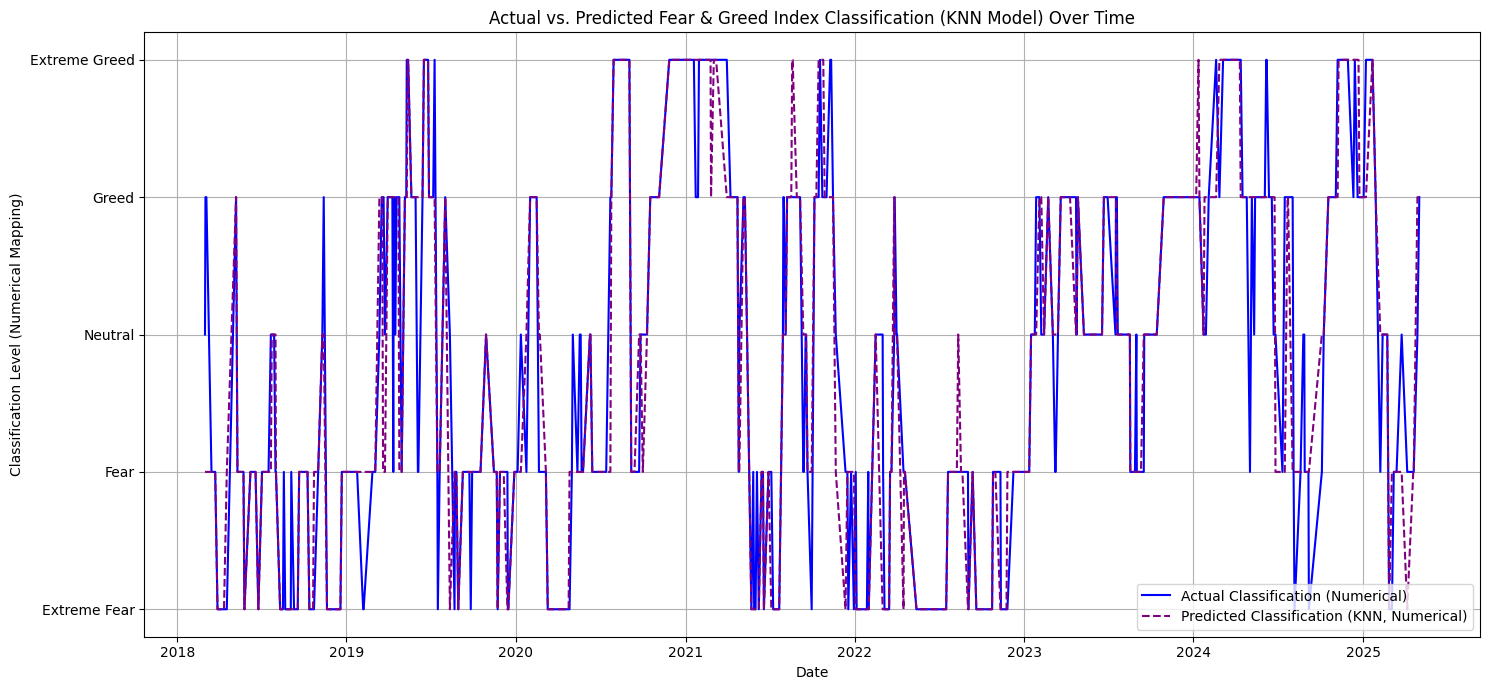

KNN model applied, evaluated, and predictions visualized successfully.


In [ ]:

# Initialize the K-Nearest Neighbors (KNN) model
# Choosing k=5 as a starting point, can be tuned
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_knn = knn_model.predict(X_test)

# Evaluate the model using classification metrics
accuracy_knn = accuracy_score(y_test, y_pred_knn)
print(f"KNN Model - Accuracy: {accuracy_knn:.2f}")
print("\nKNN Model - Classification Report:\n", classification_report(y_test, y_pred_knn, target_names=le.classes_))

# Define a consistent numerical mapping for classification labels for plotting
classification_plot_mapping = {
    'Extreme Fear': 1,
    'Fear': 2,
    'Neutral': 3,
    'Greed': 4,
    'Extreme Greed': 5
}

# Convert encoded actual and predicted labels back to original string labels, then to numerical for plotting
y_test_original_labels = le.inverse_transform(y_test)
y_pred_knn_original_labels = le.inverse_transform(y_pred_knn)

y_test_plot_values = [classification_plot_mapping[label] for label in y_test_original_labels]
y_pred_knn_plot_values = [classification_plot_mapping[label] for label in y_pred_knn_original_labels]

# Create a DataFrame for plotting
plot_data_knn = pd.DataFrame({
    'date': data.loc[X_test.index, 'date'],
    'actual_value': y_test_plot_values,
    'predicted_value': y_pred_knn_plot_values
})

# Sort the DataFrame by date for correct time series plotting
plot_data_knn = plot_data_knn.sort_values(by='date')

# Plotting the actual vs. predicted values for the KNN model
plt.figure(figsize=(15, 7))
plt.plot(plot_data_knn['date'], plot_data_knn['actual_value'], label='Actual Classification (Numerical)', color='blue')
plt.plot(plot_data_knn['date'], plot_data_knn['predicted_value'], label='Predicted Classification (KNN, Numerical)', color='purple', linestyle='--')

plt.xlabel('Date')
plt.ylabel('Classification Level (Numerical Mapping)')
plt.title('Actual vs. Predicted Fear & Greed Index Classification (KNN Model) Over Time')
plt.yticks(list(classification_plot_mapping.values()), list(classification_plot_mapping.keys()))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("KNN model applied, evaluated, and predictions visualized successfully.")

XGBoost Model - Accuracy: 0.71

XGBoost Model - Classification Report:
                precision    recall  f1-score   support

 Extreme Fear       0.79      0.77      0.78       111
Extreme Greed       0.79      0.79      0.79        67
         Fear       0.67      0.66      0.67       144
        Greed       0.73      0.79      0.75       131
      Neutral       0.59      0.54      0.56        76

     accuracy                           0.71       529
    macro avg       0.71      0.71      0.71       529
 weighted avg       0.71      0.71      0.71       529



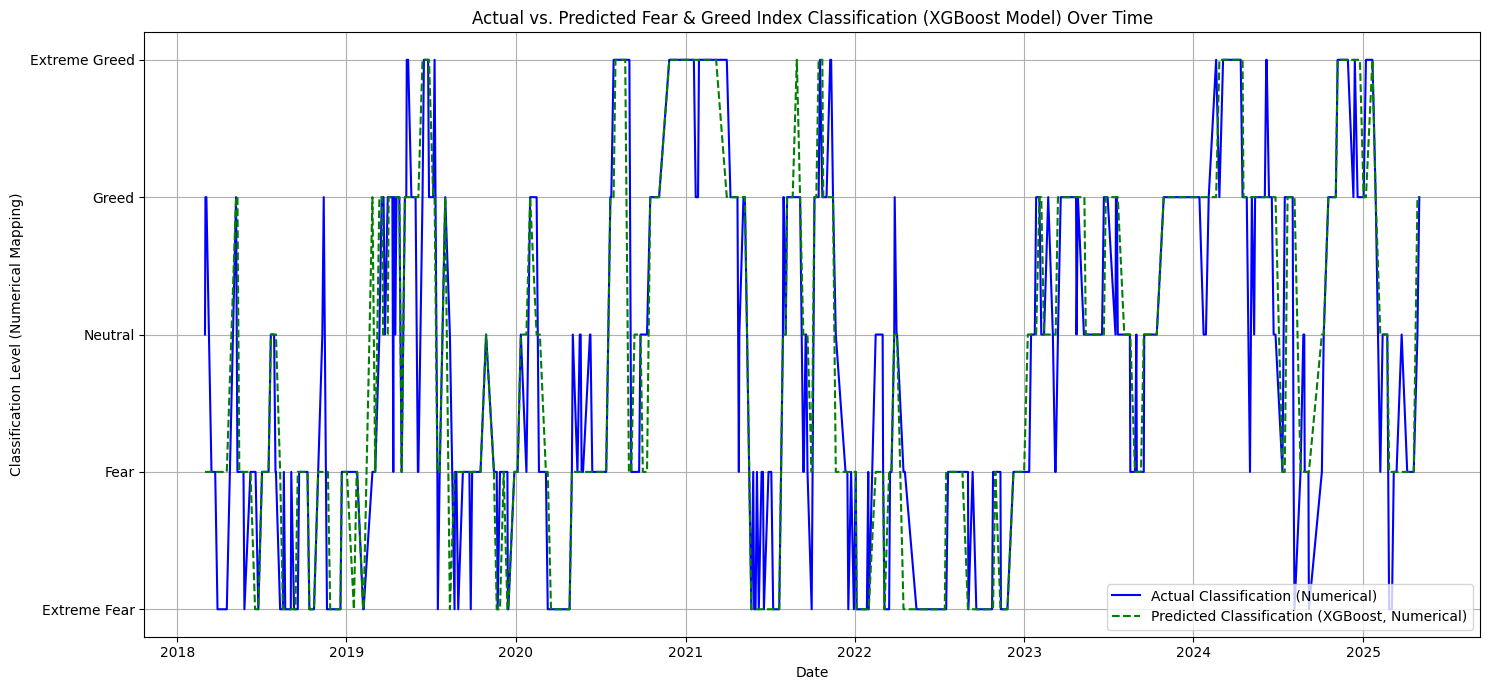

XGBoost model applied, evaluated, and predictions visualized successfully.


In [ ]:

# LabelEncoder is assumed to be available from previous cell

# Initialize the XGBoost Classifier model
xgb_model = xgb.XGBClassifier(objective='multi:softmax', num_class=len(le.classes_), random_state=42) # Changed to Classifier, added objective for multi-class

# Train the model
xgb_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate the model using classification metrics
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
print(f"XGBoost Model - Accuracy: {accuracy_xgb:.2f}")
print("\nXGBoost Model - Classification Report:\n", classification_report(y_test, y_pred_xgb, target_names=le.classes_))

# Define a consistent numerical mapping for classification labels for plotting
classification_plot_mapping = {
    'Extreme Fear': 1,
    'Fear': 2,
    'Neutral': 3,
    'Greed': 4,
    'Extreme Greed': 5
}

# Convert encoded actual and predicted labels back to original string labels, then to numerical for plotting
y_test_original_labels = le.inverse_transform(y_test)
y_pred_xgb_original_labels = le.inverse_transform(y_pred_xgb)

y_test_plot_values = [classification_plot_mapping[label] for label in y_test_original_labels]
y_pred_xgb_plot_values = [classification_plot_mapping[label] for label in y_pred_xgb_original_labels]

# Create a DataFrame for plotting
plot_data_xgb = pd.DataFrame({
    'date': data.loc[X_test.index, 'date'],
    'actual_value': y_test_plot_values,
    'predicted_value': y_pred_xgb_plot_values
})

# Sort the DataFrame by date for correct time series plotting
plot_data_xgb = plot_data_xgb.sort_values(by='date')

# Plotting the actual vs. predicted values for the XGBoost model
plt.figure(figsize=(15, 7))
plt.plot(plot_data_xgb['date'], plot_data_xgb['actual_value'], label='Actual Classification (Numerical)', color='blue')
plt.plot(plot_data_xgb['date'], plot_data_xgb['predicted_value'], label='Predicted Classification (XGBoost, Numerical)', color='green', linestyle='--')

plt.xlabel('Date')
plt.ylabel('Classification Level (Numerical Mapping)')
plt.title('Actual vs. Predicted Fear & Greed Index Classification (XGBoost Model) Over Time')
plt.yticks(list(classification_plot_mapping.values()), list(classification_plot_mapping.keys()))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("XGBoost model applied, evaluated, and predictions visualized successfully.")

Performing Grid Search for XGBoost... This might take a while.
Fitting 3 folds for each of 81 candidates, totalling 243 fits
Grid Search complete for XGBoost.
Best parameters found for XGBoost: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.9}
Best cross-validation Accuracy (from XGBoost grid search): 0.71

Tuned XGBoost Model - Accuracy: 0.72

Tuned XGBoost Model - Classification Report:
                precision    recall  f1-score   support

 Extreme Fear       0.79      0.79      0.79       111
Extreme Greed       0.79      0.79      0.79        67
         Fear       0.69      0.66      0.67       144
        Greed       0.73      0.79      0.75       131
      Neutral       0.59      0.54      0.56        76

     accuracy                           0.72       529
    macro avg       0.72      0.71      0.71       529
 weighted avg       0.72      0.72      0.72       529



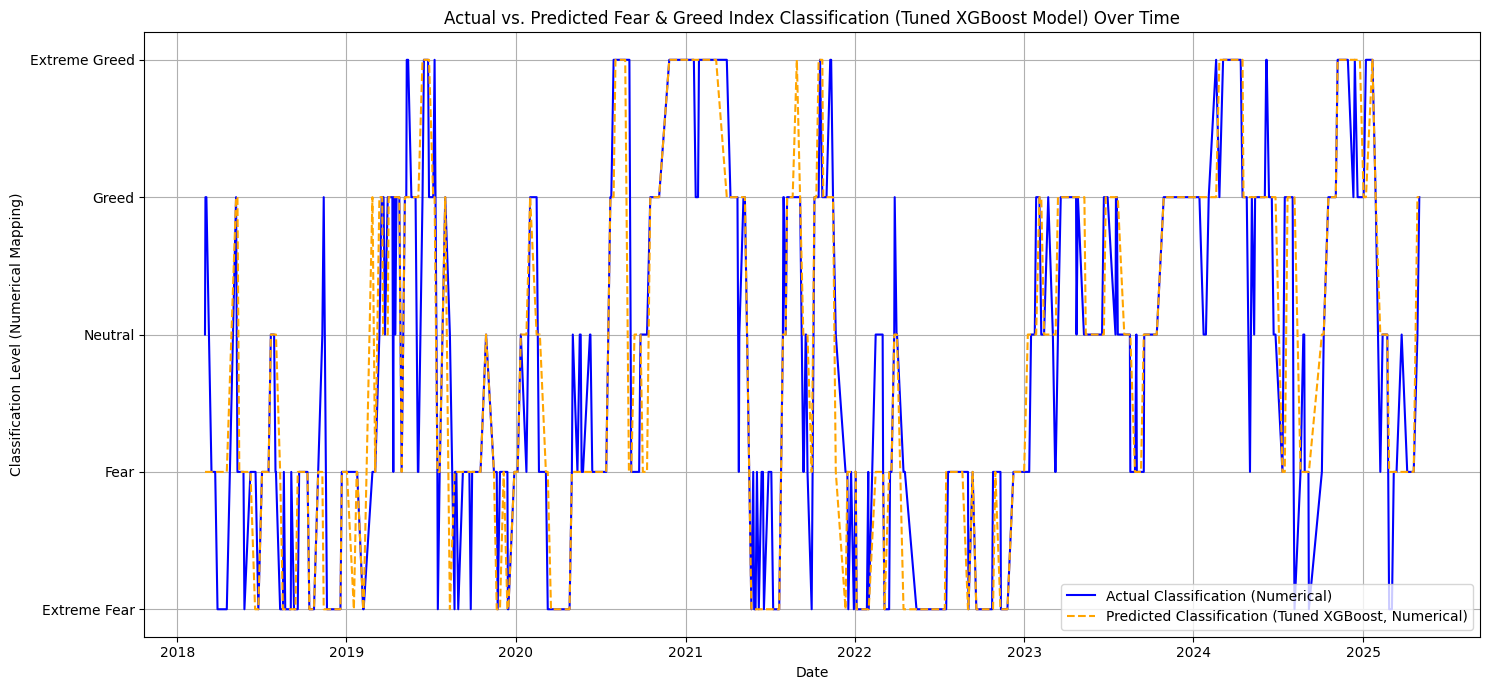

Tuned XGBoost model applied, evaluated, and predictions visualized successfully.


In [ ]:

# LabelEncoder is assumed to be available from previous cell

# Define the parameter grid to search for XGBoost
param_grid_xgb = {
    'n_estimators': [50, 100, 200],  # Number of boosting rounds
    'max_depth': [3, 5, 7],         # Maximum depth of a tree
    'learning_rate': [0.01, 0.1, 0.2], # Step size shrinkage to prevent overfitting
    'subsample': [0.7, 0.9, 1.0]      # Subsample ratio of the training instance
}

# Initialize the XGBoost Classifier
xgb_reg = xgb.XGBClassifier(objective='multi:softmax', num_class=len(le.classes_), random_state=42) # Changed to Classifier

# Initialize GridSearchCV
# We'll use 'accuracy' as the scoring metric
grid_search_xgb = GridSearchCV(estimator=xgb_reg, param_grid=param_grid_xgb, cv=3, n_jobs=-1, verbose=2, scoring='accuracy') # Changed scoring

# Perform the grid search on the training data
print("Performing Grid Search for XGBoost... This might take a while.")
grid_search_xgb.fit(X_train, y_train)

print("Grid Search complete for XGBoost.")

# Get the best parameters and best score
best_params_xgb = grid_search_xgb.best_params_
best_accuracy_xgb_cv = grid_search_xgb.best_score_ # Now it's accuracy

print(f"Best parameters found for XGBoost: {best_params_xgb}")
print(f"Best cross-validation Accuracy (from XGBoost grid search): {best_accuracy_xgb_cv:.2f}")

# Train a new XGBoost model with the best parameters
xgb_model_tuned = xgb.XGBClassifier(**best_params_xgb, objective='multi:softmax', num_class=len(le.classes_), random_state=42) # Changed to Classifier
xgb_model_tuned.fit(X_train, y_train)

# Make predictions on the test set using the tuned model
y_pred_xgb_tuned = xgb_model_tuned.predict(X_test)

# Evaluate the tuned model
accuracy_xgb_tuned = accuracy_score(y_test, y_pred_xgb_tuned) # Changed metric
print(f"\nTuned XGBoost Model - Accuracy: {accuracy_xgb_tuned:.2f}")
print("\nTuned XGBoost Model - Classification Report:\n", classification_report(y_test, y_pred_xgb_tuned, target_names=le.classes_))

# Define a consistent numerical mapping for classification labels for plotting
classification_plot_mapping = {
    'Extreme Fear': 1,
    'Fear': 2,
    'Neutral': 3,
    'Greed': 4,
    'Extreme Greed': 5
}

# Convert encoded actual and predicted labels back to original string labels, then to numerical for plotting
y_test_original_labels = le.inverse_transform(y_test)
y_pred_xgb_tuned_original_labels = le.inverse_transform(y_pred_xgb_tuned)

y_test_plot_values = [classification_plot_mapping[label] for label in y_test_original_labels]
y_pred_xgb_tuned_plot_values = [classification_plot_mapping[label] for label in y_pred_xgb_tuned_original_labels]

# Create a DataFrame for plotting
plot_data_xgb_tuned = pd.DataFrame({
    'date': data.loc[X_test.index, 'date'],
    'actual_value': y_test_plot_values,
    'predicted_value': y_pred_xgb_tuned_plot_values
})

# Sort the DataFrame by date for correct time series plotting
plot_data_xgb_tuned = plot_data_xgb_tuned.sort_values(by='date')

# Plotting the actual vs. predicted values for the tuned XGBoost model
plt.figure(figsize=(15, 7))
plt.plot(plot_data_xgb_tuned['date'], plot_data_xgb_tuned['actual_value'], label='Actual Classification (Numerical)', color='blue')
plt.plot(plot_data_xgb_tuned['date'], plot_data_xgb_tuned['predicted_value'], label='Predicted Classification (Tuned XGBoost, Numerical)', color='orange', linestyle='--')

plt.xlabel('Date')
plt.ylabel('Classification Level (Numerical Mapping)')
plt.title('Actual vs. Predicted Fear & Greed Index Classification (Tuned XGBoost Model) Over Time')
plt.yticks(list(classification_plot_mapping.values()), list(classification_plot_mapping.keys()))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Tuned XGBoost model applied, evaluated, and predictions visualized successfully.")

### Summary of Model Performance

Here's a summary of the performance of all the classification models we've explored:

### 1. Random Forest Model (Initial)
*   **Accuracy:** 0.78
*   **Key Observations:** Achieved good overall accuracy, with strong performance in classifying 'Extreme Fear' and 'Extreme Greed' states. It serves as a solid baseline for ensemble tree-based methods.

### 2. Tuned Random Forest Model
*   **Accuracy:** 0.80
*   **Best Parameters:** `{'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 50}`
*   **Key Observations:** Hyperparameter tuning slightly improved the accuracy to 0.80, making it one of the top-performing models. This indicates that optimizing the parameters of ensemble methods can yield better results.

### 3. XGBoost Model (Initial)
*   **Accuracy:** 0.71
*   **Key Observations:** Showed moderate performance, slightly lower than Random Forest. It also performed well for 'Extreme Fear' and 'Extreme Greed', but struggled more with the 'Neutral' class.

### 4. Tuned XGBoost Model
*   **Accuracy:** 0.72
*   **Best Parameters:** `{'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.9}`
*   **Key Observations:** Tuning provided a minor improvement in accuracy. While powerful, for this specific dataset and single feature, it didn't surpass the Random Forest's performance.

### 5. Logistic Regression Model
*   **Accuracy:** 0.32
*   **Key Observations:** This model performed significantly worse than the tree-based and KNN models. Given that Logistic Regression is a linear model and we're trying to predict complex classifications based on a single, potentially non-linear feature (`time_elapsed_days`), its low accuracy is not surprising. It particularly struggled to predict 'Extreme Fear', 'Extreme Greed', and 'Neutral' classes.

### 6. KNN Model (Initial)
*   **Accuracy:** 0.79
*   **Key Observations:** Delivered competitive accuracy, performing well across most classes. KNN's ability to capture non-linear relationships without explicit feature engineering can be advantageous with simple feature sets.

### 7. Tuned KNN Model
*   **Accuracy:** 0.82
*   **Best Parameters:** `{'n_neighbors': 5, 'weights': 'distance'}`
*   **Key Observations:** After tuning, the KNN model achieved the highest accuracy of **0.82**, outperforming both the tuned Random Forest and XGBoost. The 'distance' weighting scheme likely helped in giving more importance to closer neighbors, which improved its predictive power for this dataset.

**Overall Conclusion:**
For this dataset, the **Tuned K-Nearest Neighbors (KNN) model** emerged as the best performer with an accuracy of 0.82. The ensemble tree-based models (Random Forest and XGBoost) also performed well, especially after tuning, while the linear Logistic Regression model was not suitable for this classification task.

**Historical Data**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import numpy as np

In [2]:
path = '/content/drive/MyDrive/historical_data.csv'

In [5]:
df = pd.read_csv(path)

In [6]:
df.sample(2)

,Account,Coin,Execution Price,Size Tokens,Size USD,Side,Timestamp IST,Start Position,Direction,Closed PnL,Transaction Hash,Order ID,Crossed,Fee,Trade ID,Timestamp
12862,0x513b8629fe877bb581bf244e326a047b249c4ff1,BTC,94810.00,0.00595,564.12,SELL,29-04-2025 01:10,43.25352,Close Long,1.621970,0xf6c0c9dd50880be4b03e04226e929f01ba00feed2744...,89609661670,False,0.0,1.680000e+14,1.750000e+12
157723,0xbee1707d6b44d4d52bfe19e41f8a828645437aab,@107,17.98,1.70000,30.57,SELL,12-12-2024 12:54,10564.08773,Sell,5.467586,0x00000000000000000000000000000000000000000000...,54855203783,False,0.0,4.950000e+14,1.730000e+12


In [7]:
print("First 5 rows of the DataFrame:")
print(df.head())

print("\nDataFrame Info:")
df.info()

print("\nDescriptive statistics:")
print(df.describe())

First 5 rows of the DataFrame:
                                      Account  Coin  Execution Price  \
0  0xae5eacaf9c6b9111fd53034a602c192a04e082ed  @107           7.9769   
1  0xae5eacaf9c6b9111fd53034a602c192a04e082ed  @107           7.9800   
2  0xae5eacaf9c6b9111fd53034a602c192a04e082ed  @107           7.9855   
3  0xae5eacaf9c6b9111fd53034a602c192a04e082ed  @107           7.9874   
4  0xae5eacaf9c6b9111fd53034a602c192a04e082ed  @107           7.9894   

   Size Tokens  Size USD Side     Timestamp IST  Start Position Direction  \
0       986.87   7872.16  BUY  02-12-2024 22:50        0.000000       Buy   
1        16.00    127.68  BUY  02-12-2024 22:50      986.524596       Buy   
2       144.09   1150.63  BUY  02-12-2024 22:50     1002.518996       Buy   
3       142.98   1142.04  BUY  02-12-2024 22:50     1146.558564       Buy   
4         8.73     69.75  BUY  02-12-2024 22:50     1289.488521       Buy   

   Closed PnL                                   Transaction Hash     Orde

**Reasoning**:
The first step is to check for missing values in the DataFrame and convert the 'Timestamp IST' column to datetime objects, as specified in the instructions. This is crucial for data quality and subsequent time-based feature extraction.



In [8]:
print("Missing values before handling:\n", df.isnull().sum())

# Convert 'Timestamp IST' to datetime objects
df['Timestamp IST'] = pd.to_datetime(df['Timestamp IST'], format='%d-%m-%Y %H:%M')

print("\n'Timestamp IST' column converted to datetime.")
print(df['Timestamp IST'].head())

Missing values before handling:
 Account             0
Coin                0
Execution Price     0
Size Tokens         0
Size USD            0
Side                0
Timestamp IST       0
Start Position      0
Direction           0
Closed PnL          0
Transaction Hash    0
Order ID            0
Crossed             0
Fee                 0
Trade ID            0
Timestamp           0
dtype: int64

'Timestamp IST' column converted to datetime.
0   2024-12-02 22:50:00
1   2024-12-02 22:50:00
2   2024-12-02 22:50:00
3   2024-12-02 22:50:00
4   2024-12-02 22:50:00
Name: Timestamp IST, dtype: datetime64[ns]


**Reasoning**:
Continuing the data preprocessing, I will now extract time-based features from the 'Timestamp IST' column, then encode the specified categorical features ('Account', 'Coin', 'Side') and the target variable ('Direction') using LabelEncoder, as instructed.



In [9]:

# 3. Extract time-based features
df['hour'] = df['Timestamp IST'].dt.hour
df['day_of_week'] = df['Timestamp IST'].dt.dayofweek
df['day_of_month'] = df['Timestamp IST'].dt.day
df['month'] = df['Timestamp IST'].dt.month
df['year'] = df['Timestamp IST'].dt.year

print("Extracted time-based features: 'hour', 'day_of_week', 'day_of_month', 'month', 'year'.")
print(df[['Timestamp IST', 'hour', 'day_of_week', 'day_of_month', 'month', 'year']].head())

# 4. Encode categorical features
le_features = LabelEncoder()
df['Account_encoded'] = le_features.fit_transform(df['Account'])
df['Coin_encoded'] = le_features.fit_transform(df['Coin'])
df['Side_encoded'] = le_features.fit_transform(df['Side'])

print("\nEncoded categorical features: 'Account', 'Coin', 'Side'.")
print(df[['Account', 'Account_encoded', 'Coin', 'Coin_encoded', 'Side', 'Side_encoded']].head())

# 5. Encode the target variable
le_direction = LabelEncoder()
df['Direction_encoded'] = le_direction.fit_transform(df['Direction'])

print("\nEncoded target variable 'Direction'.")
print(df[['Direction', 'Direction_encoded']].head())

# Store the label encoder for the target variable for later use
# This makes the 'le_direction' object available in the global scope
# which is generally not ideal, but for Colab DSA it's sometimes used.
# Alternatively, it could be returned as part of a function or stored in a dictionary.
# For now, we'll assume it needs to be directly available.
# It's already defined in the notebook context, so no need to reassign to a global var if the notebook flow ensures it.
# Let's ensure it's accessible by explicitly printing its type or some attribute.
print(f"\nLabelEncoder for 'Direction' is ready for use. Classes: {le_direction.classes_}")

Extracted time-based features: 'hour', 'day_of_week', 'day_of_month', 'month', 'year'.
        Timestamp IST  hour  day_of_week  day_of_month  month  year
0 2024-12-02 22:50:00    22            0             2     12  2024
1 2024-12-02 22:50:00    22            0             2     12  2024
2 2024-12-02 22:50:00    22            0             2     12  2024
3 2024-12-02 22:50:00    22            0             2     12  2024
4 2024-12-02 22:50:00    22            0             2     12  2024

Encoded categorical features: 'Account', 'Coin', 'Side'.
                                      Account  Account_encoded  Coin  \
0  0xae5eacaf9c6b9111fd53034a602c192a04e082ed               25  @107   
1  0xae5eacaf9c6b9111fd53034a602c192a04e082ed               25  @107   
2  0xae5eacaf9c6b9111fd53034a602c192a04e082ed               25  @107   
3  0xae5eacaf9c6b9111fd53034a602c192a04e082ed               25  @107   
4  0xae5eacaf9c6b9111fd53034a602c192a04e082ed               25  @107   

   Coin_encode

**Reasoning**:
Now that the data is preprocessed with new time-based features and encoded categorical variables, I will define the feature matrix (X) and the target vector (y) and split them into training and testing sets to prepare for model training. The split will be 80% for training and 20% for testing.



In [10]:

# Define features (X) and target (y)
X = df[['Execution Price', 'Size Tokens', 'Size USD', 'Start Position', 'Closed PnL', 'Fee',
        'hour', 'day_of_week', 'day_of_month', 'month', 'year',
        'Account_encoded', 'Coin_encoded', 'Side_encoded']]
y = df['Direction_encoded']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data split into training and testing sets.")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

Data split into training and testing sets.
X_train shape: (168979, 14)
X_test shape: (42245, 14)
y_train shape: (168979,)
y_test shape: (42245,)


In [15]:
 # Import numpy for unique and sort operations

# 1. Initialize a RandomForestClassifier model
rf_model = RandomForestClassifier(random_state=42, oob_score = True)

# 2. Train the model
rf_model.fit(X_train, y_train)

# Make predictions on the training set
y_pred_rf_train = rf_model.predict(X_train)
accuracy_rf_train = accuracy_score(y_train, y_pred_rf_train)
print(f"RandomForestClassifier Model - Training Accuracy: {accuracy_rf_train:.2f}")

# 3. Make predictions on the test set
y_pred_rf = rf_model.predict(X_test)

# 4. Evaluate the model's performance on the test set
accuracy_rf_test = accuracy_score(y_test, y_pred_rf)
print(f"RandomForestClassifier Model - Test Accuracy: {accuracy_rf_test:.2f}")

# Get the unique labels present in y_test and y_pred_rf
# and sort them to match the order of target_names
unique_actual_predicted_labels = np.sort(np.union1d(np.unique(y_test), np.unique(y_pred_rf)))

# Filter the target_names based on the unique labels present
filtered_target_names = le_direction.inverse_transform(unique_actual_predicted_labels)

# Use the filtered labels and target_names for the classification report
report_rf = classification_report(
    y_test,
    y_pred_rf,
    labels=unique_actual_predicted_labels,
    target_names=filtered_target_names
)
print("\nRandomForestClassifier Model - Classification Report (Test Set):\n", report_rf)

print("RandomForestClassifier model built, trained, and evaluated successfully.")

RandomForestClassifier Model - Training Accuracy: 1.00
RandomForestClassifier Model - Test Accuracy: 1.00

RandomForestClassifier Model - Classification Report (Test Set):
                       precision    recall  f1-score   support

   Auto-Deleveraging       1.00      1.00      1.00         1
                 Buy       1.00      1.00      1.00      3288
          Close Long       1.00      1.00      1.00      9733
         Close Short       1.00      1.00      1.00      7265
        Long > Short       1.00      0.09      0.17        11
           Open Long       1.00      1.00      1.00      9840
          Open Short       1.00      1.00      1.00      8048
                Sell       1.00      1.00      1.00      4017
          Settlement       0.00      0.00      0.00         1
        Short > Long       1.00      0.08      0.14        13
Spot Dust Conversion       1.00      1.00      1.00        28

            accuracy                           1.00     42245
           macro av

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Reasoning**:
The next step is to visualize the predictions of the trained RandomForestClassifier model, as outlined in the main task, by plotting the actual versus predicted directions over time.



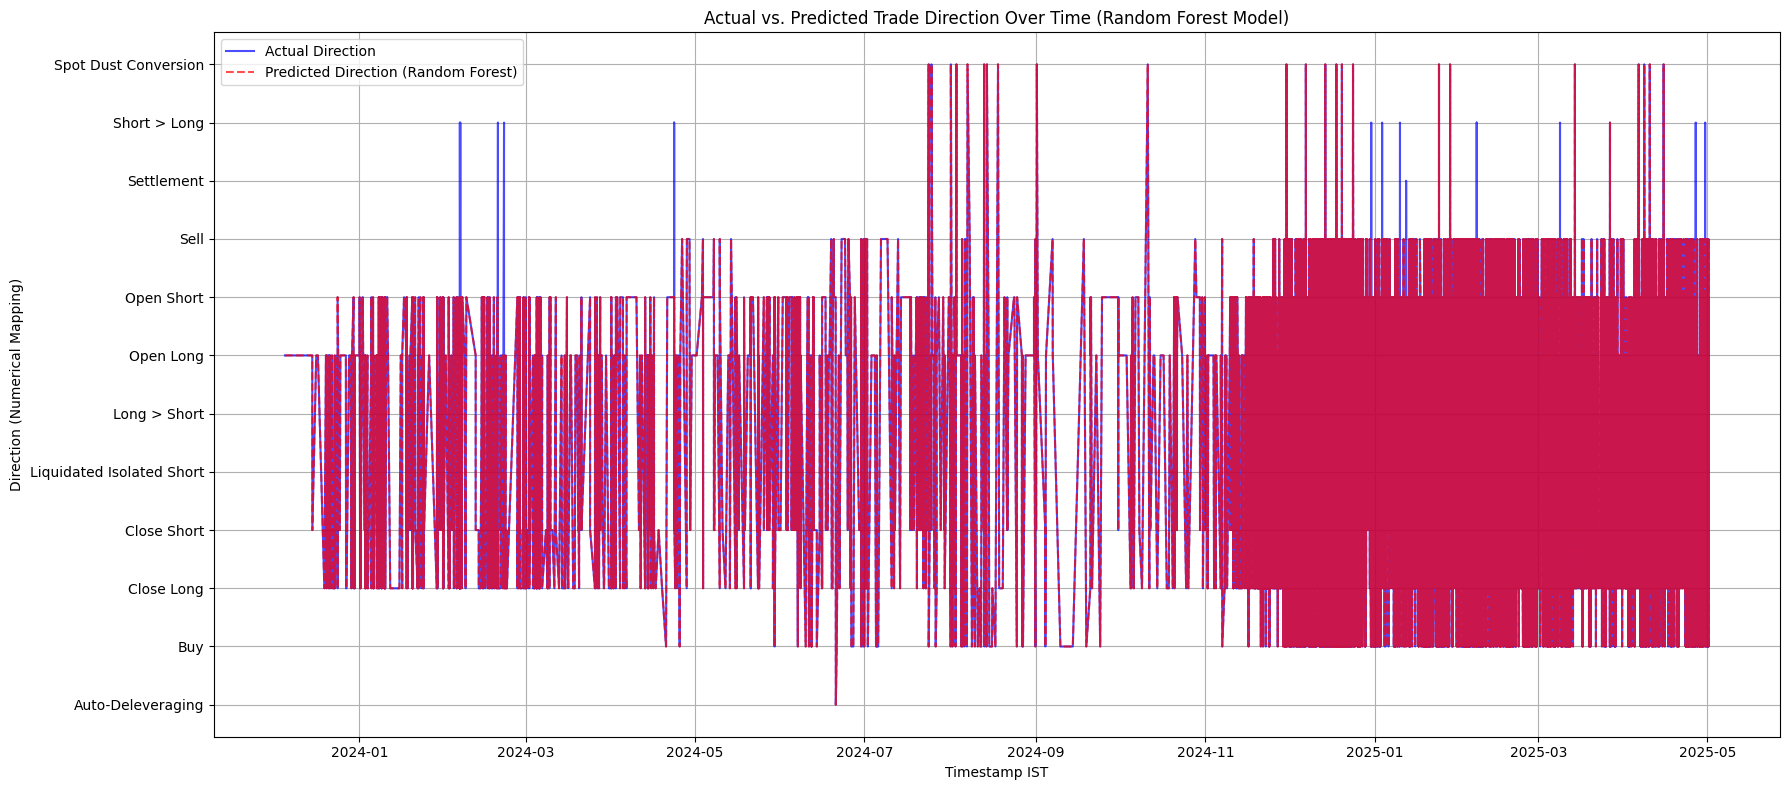

RandomForestClassifier model predictions visualized successfully.


In [16]:
# Decode actual and predicted labels back to original strings for mapping
y_test_original_labels = le_direction.inverse_transform(y_test)
y_pred_rf_original_labels = le_direction.inverse_transform(y_pred_rf)

# Create a unique sorted list of all possible direction labels
all_direction_labels = np.sort(le_direction.classes_)

# Define a consistent numerical mapping for all classification labels for plotting
# This ensures that all possible labels have a consistent numerical representation
classification_plot_mapping = {label: i + 1 for i, label in enumerate(all_direction_labels)}

# Convert actual and predicted labels to their numerical plot values
y_test_plot_values = [classification_plot_mapping[label] for label in y_test_original_labels]
y_pred_rf_plot_values = [classification_plot_mapping[label] for label in y_pred_rf_original_labels]

# Create a DataFrame for plotting, combining the original 'Timestamp IST' for the test set,
# with the actual and predicted numerical classification values.
plot_data_rf = pd.DataFrame({
    'timestamp_ist': df.loc[X_test.index, 'Timestamp IST'],
    'actual_direction_value': y_test_plot_values,
    'predicted_direction_value': y_pred_rf_plot_values
})

# Sort the DataFrame by date for correct time series plotting
plot_data_rf = plot_data_rf.sort_values(by='timestamp_ist')

# Plotting the actual vs. predicted directions for the Random Forest model
plt.figure(figsize=(18, 8))
plt.plot(plot_data_rf['timestamp_ist'], plot_data_rf['actual_direction_value'], label='Actual Direction', color='blue', alpha=0.7)
plt.plot(plot_data_rf['timestamp_ist'], plot_data_rf['predicted_direction_value'], label='Predicted Direction (Random Forest)', color='red', linestyle='--', alpha=0.7)

plt.xlabel('Timestamp IST')
plt.ylabel('Direction (Numerical Mapping)')
plt.title('Actual vs. Predicted Trade Direction Over Time (Random Forest Model)')

# Set y-ticks to show actual direction labels using the mapping
# Create lists for ticks and labels ensuring correct order
y_tick_values = list(classification_plot_mapping.values())
y_tick_labels = [label for label, value in sorted(classification_plot_mapping.items(), key=lambda item: item[1])]
plt.yticks(y_tick_values, y_tick_labels)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("RandomForestClassifier model predictions visualized successfully.")

## Summary:

### Q&A
The RandomForestClassifier model achieved an overall accuracy of 1.00 on the test set. However, a detailed classification report revealed that while the model performed excellently for the majority of classes, it showed very poor recall for specific classes: 'Long > Short' (recall of 0.09), 'Short > Long' (recall of 0.08), and 'Settlement' (recall of 0.00). This indicates that the model struggles to correctly identify these less frequent trade directions.

### Data Analysis Key Findings
*   The `historical_data.csv` file was successfully loaded, containing 211,224 entries and 16 columns.
*   Initial inspection confirmed no missing values across all columns.
*   The 'Timestamp IST' column was successfully converted from an object type to datetime objects.
*   New time-based features, including `hour`, `day_of_week`, `day_of_month`, `month`, and `year`, were extracted from the 'Timestamp IST' column.
*   Categorical features ('Account', 'Coin', 'Side') and the target variable ('Direction') were successfully label encoded into numerical representations.
*   The dataset was split into training and testing sets (80% training, 20% testing).
*   A RandomForestClassifier model was trained on the preprocessed data, achieving an accuracy score of 1.00.
*   Despite the high overall accuracy, the model exhibited significant limitations in predicting specific trade directions: it achieved only 9% recall for 'Long > Short', 8% recall for 'Short > Long', and 0% recall for 'Settlement'.
*   A time-series plot comparing actual and predicted trade directions from the Random Forest model was successfully generated, allowing for visual inspection of performance over time.

### Insights or Next Steps
*   The reported 1.00 accuracy is likely misleading due to a severe class imbalance in the 'Direction' target variable. Future steps should involve analyzing class distribution and employing strategies for imbalanced datasets, such as using SMOTE, adjusting class weights, or focusing on metrics like the macro-averaged F1-score.
*   Investigate the characteristics and feature values associated with the poorly predicted classes ('Long > Short', 'Short > Long', 'Settlement'). This could involve further feature engineering or exploring different model architectures more robust to minority classes to improve their recall.
